# Hito 2 · Puntualidad y confiabilidad de vuelos
Análisis reproducible del JSON adjunto y traducción crítica del wireframe HTML. Objetivo: identificar patrones operacionales sin confundir datos simulados, resúmenes auxiliares ni registros inconsistentes con evidencia válida. La fuente primaria y el universo de cobertura no están acreditados.

**Estado:** aplicación implementada para ejecución local; publicación y URL pública pendientes. No se asegura una calificación.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT/'src/analysis.py').exists():
    raise RuntimeError('Ejecuta el notebook desde la carpeta HITO2_Vuelos')
sys.path.insert(0,str(ROOT))
from src.analysis import *
from IPython.display import display
from IPython.core.pylabtools import print_figure
get_ipython().display_formatter.formatters["image/png"].for_type(plt.Figure, lambda fig: print_figure(fig, "png"))
raw,audit,payload=load()
print('Filas originales:',len(raw))
display(raw.head())

Filas originales: 3344


,Year,Month,Airline,OriginState,Haul,ops,ontime,delayed15,delayed60,cancel,divert,sumDelayMin,carrierDelay,weatherDelay,nasDelay,secDelay,lateAirDelay
0,2021,4,9E,US,corto,16424,15656.0,753.0,265.0,0.0,15.0,52108.0,28448.0,4881.0,6216.0,45.0,12518.0
1,2021,4,AA,US,corto,10420,9292.0,1070.0,323.0,50.0,8.0,76895.0,32925.0,5423.0,13806.0,164.0,24577.0
2,2021,4,AS,US,corto,1643,1408.0,205.0,48.0,23.0,7.0,10205.0,3856.0,114.0,1596.0,372.0,4267.0
3,2021,4,B6,US,medio,10556,8422.0,1997.0,813.0,106.0,31.0,165696.0,62055.0,13713.0,30476.0,4093.0,55359.0
4,2021,4,B6,US,largo,3646,3148.0,478.0,129.0,12.0,8.0,28645.0,14139.0,568.0,4426.0,555.0,8957.0


## Preparación y auditoría
Unidad: año × mes × aerolínea × OriginState × alcance. OriginState solo contiene US; no permite un mapa estatal. Se validan esquema, tipos, finitud, no negatividad, conteos enteros, clave única, fecha, balance de estados, subconjunto de demoras y balance de minutos. No se imputan valores ni se sustituyen por los ejemplos del HTML. Los umbrales y supuestos son reproducibles en `src/analysis.py`. La concordancia de causas con sumDelayMin es un supuesto de consistencia inferido del uso del HTML, no una garantía del proveedor.

In [2]:
valid= audit[audit.valid].copy()
display(audit.groupby('Year').agg(filas=('valid','size'),validas=('valid','sum')))
display(audit.loc[~audit.valid,['source_row','Year','Month','Airline','issues']].head(15))
print('Exclusiones:',int((~audit.valid).sum()), 'de',len(audit))
display(pd.DataFrame([metrics(audit),metrics(valid)],index=['Original diagnóstico','Validado principal']))

Exclusiones: 142 de 3344


,filas,validas
Year,,
2021,665,664
2022,654,653
2023,501,376
2024,645,643
2025,629,624
2026,250,242


,source_row,Year,Month,Airline,issues
55,56,2023,4,AS,balance_estados; balance_causas
56,57,2023,4,DL,balance_causas
57,58,2023,4,HA,balance_estados; balance_causas
58,59,2023,4,NK,balance_estados; balance_causas
59,60,2023,4,OO,balance_estados; balance_causas
60,61,2023,4,UA,balance_causas
133,134,2026,4,WN,balance_causas
134,135,2026,4,WN,balance_causas
464,465,2023,2,OO,balance_estados; balance_causas
465,466,2023,2,UA,balance_causas


,Operaciones,Puntualidad,Cancelación,Demora media en retrasados
Original diagnóstico,38382189,79.340824,1.683137,70.769818
Validado principal,35436522,78.084745,1.804268,71.088958


Se excluyen 142 filas con 2.945.667 operaciones (7,67% del volumen original). En 2023, 125 de 501 filas fallan: la puntualidad bruta de 86,56% pasa a 79,52% en el subconjunto. El cambio no demuestra el valor verdadero: excluir filas genera sesgo de selección. Se conservan los originales y todas las incidencias para solicitar corrección al proveedor.

## KPI y metodología
Puntualidad = Σontime/Σops × 100; cancelación = Σcancel/Σops ×100; demora media = ΣsumDelayMin/Σdelayed15. Nunca se promedian porcentajes de filas. El atraso ≥60 es subconjunto del atraso ≥15. `ontime` se interpreta siguiendo el HTML como demora menor de 15 minutos, sin cancelación ni desvío, sin posibilidad de verificarlo a nivel de vuelo.

**Incertidumbre:** Wilson 95% con z=1,95996, p=k/n, centro=(p+z²/(2n))/(1+z²/n), semiancho=z·√[p(1−p)/n+z²/(4n²)]/(1+z²/n). Supone ensayos binomiales independientes y población de proceso estable. No corrige agrupación por clima/día/ruta, sesgo ni errores. Si son datos censales, la tasa es descriptiva; el intervalo ilustra un proceso hipotético. No se usa desviación mensual como intervalo de confianza.

## 01 Evolución mensual
**Pregunta:** ¿En qué meses se observa menor puntualidad?

**Elección visual:** La línea ordena los meses reales y conserva los huecos; permite distinguir oscilaciones de cambios sostenidos.

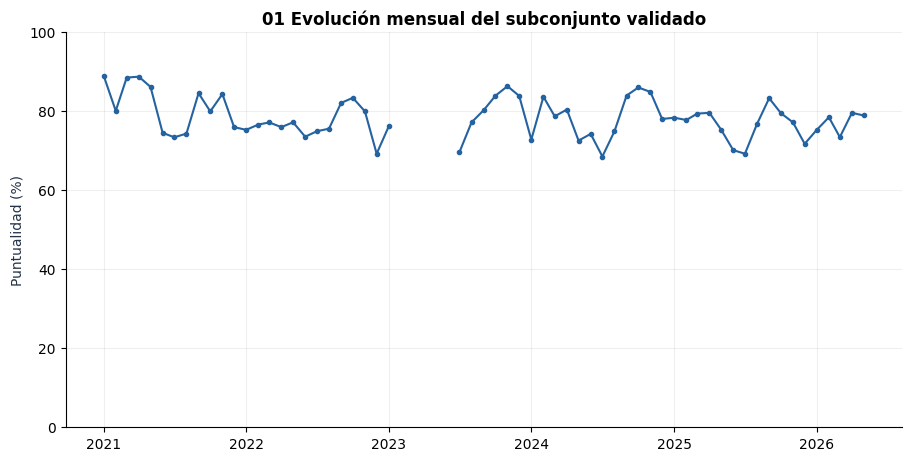

In [3]:
fig=figure(1,valid,raw,payload)
display(fig)
plt.close(fig)

**Interpretación:** Julio de 2024 presenta la menor puntualidad validada, 68,53%, frente al 89,00% de enero de 2021. Esto orienta la revisión de episodios operacionales. La composición y la cobertura cambian; no es una estimación causal ni una serie de vuelos individuales. De febrero a junio de 2023 no quedan filas válidas; el hueco no se interpola.

## 02 Comparación de abril
**Pregunta:** ¿Cómo cambia un mismo mes entre años con segmentos comunes?

**Elección visual:** Las barras comparan abril y restringen el análisis a combinaciones aerolínea y alcance presentes en los cinco años con abril válido (2021, 2022, 2024, 2025 y 2026).

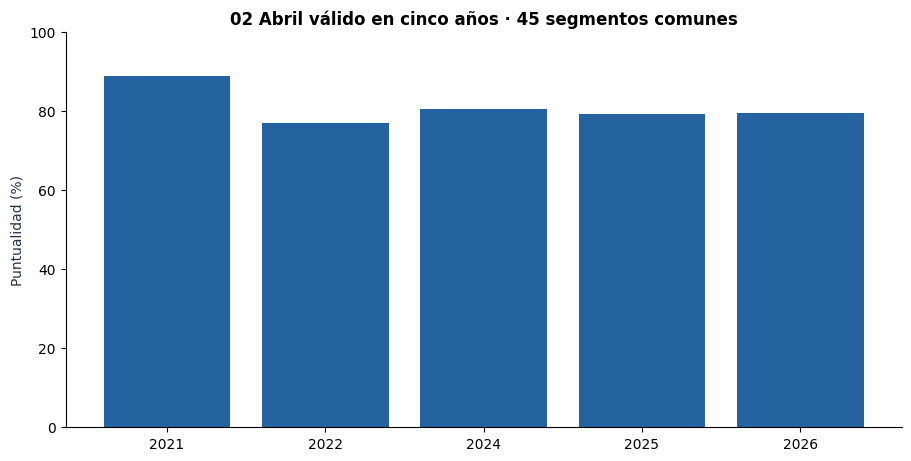

In [4]:
fig=figure(2,valid,raw,payload)
display(fig)
plt.close(fig)

**Interpretación:** Se retienen 45 segmentos comunes. 2021: 88.80%; 2022: 77.06%; 2024: 80.50%; 2025: 79.38%; 2026: 79.59%. La restricción mejora la comparabilidad, pero las ponderaciones por operaciones siguen cambiando. No equivale a ajustar rutas o aeropuertos. Abril de 2023 queda excluido porque no tiene filas válidas.

## 03 Aerolíneas e incertidumbre
**Pregunta:** ¿Qué diferencias de puntualidad tienen respaldo de volumen?

**Elección visual:** Puntos e intervalos Wilson al 95% muestran simultáneamente tasa y precisión condicional.

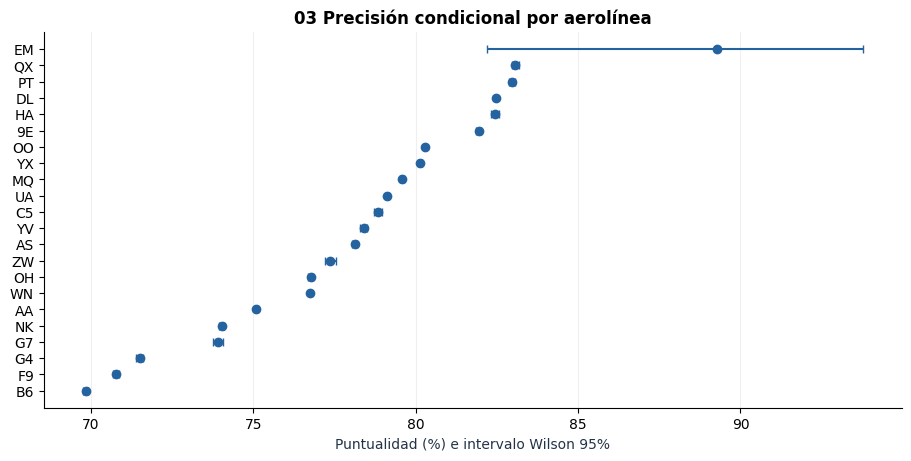

In [5]:
fig=figure(3,valid,raw,payload)
display(fig)
plt.close(fig)

**Interpretación:** EM tiene 89,29% con solo 112 operaciones y un intervalo de 82,20–93,76%; no debe declararse ganadora por el valor puntual. QX registra 83,06% en 461.193 operaciones. B6 presenta 69,83%. Las diferencias pueden reflejar mezcla de rutas y períodos.

## 04 Alcance del vuelo
**Pregunta:** ¿Se relaciona el alcance con la puntualidad observada?

**Elección visual:** Barras con base cero facilitan comparar tres categorías sin exagerar las diferencias.

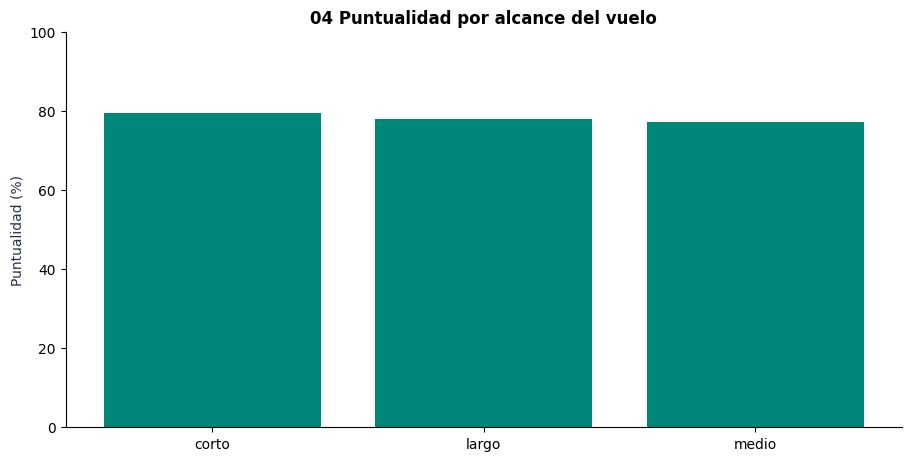

In [6]:
fig=figure(4,valid,raw,payload)
display(fig)
plt.close(fig)

**Interpretación:** Corto alcanza 79,48%, largo 77,98% y medio 77,10%. La brecha corto–medio es 2,38 puntos porcentuales. Es una asociación del agregado; los umbrales de distancia que definen las categorías no figuran en los adjuntos.

## 05 Resultado de las operaciones
**Pregunta:** ¿Qué fracción es puntual, retrasada, cancelada o desviada?

**Elección visual:** Barras horizontales usan categorías excluyentes: demora 15–59 se calcula restando demora ≥60 de demora ≥15.

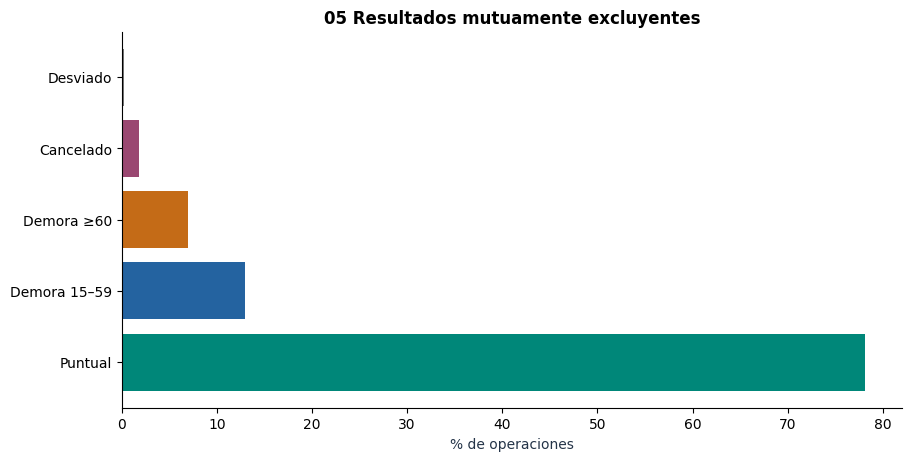

In [7]:
fig=figure(5,valid,raw,payload)
display(fig)
plt.close(fig)

**Interpretación:** La puntualidad del subconjunto es 78,08% y la cancelación 1,80%. Los retrasos ≥60 ya están incluidos en los retrasos ≥15 y no se suman dos veces. La tasa describe operaciones incluidas y no solo vuelos completados.

## 06 Causas de demora
**Pregunta:** ¿Dónde se concentra el tiempo atribuido de demora?

**Elección visual:** Barras porcentuales permiten comparar la contribución de cinco categorías al total de minutos.

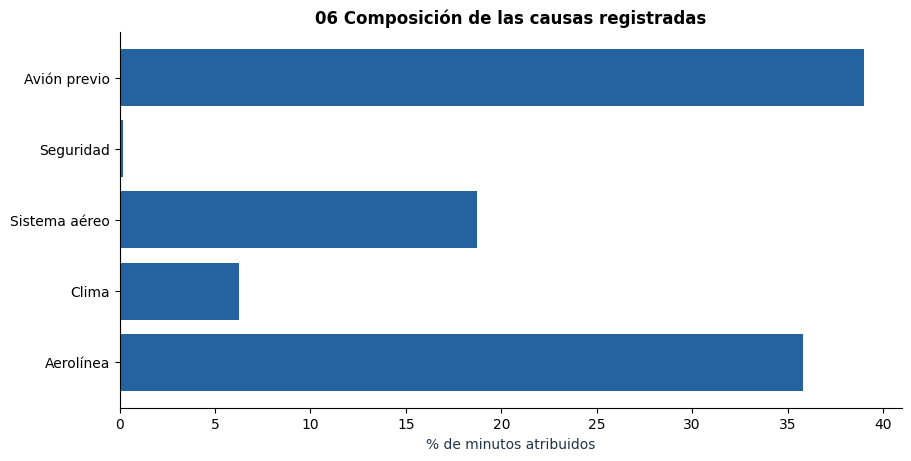

In [8]:
fig=figure(6,valid,raw,payload)
display(fig)
plt.close(fig)

**Interpretación:** Avión previo representa 39,03% y aerolínea 35,81%: juntas suman 74,84%. Conviene investigar la rotación de aeronaves y los procesos internos antes de proponer medidas. La etiqueta administrativa no demuestra causalidad; no se compara con filas cuyos minutos no concilian.

## 07 Volumen y desempeño
**Pregunta:** ¿Las aerolíneas de mayor volumen son también las más puntuales?

**Elección visual:** La dispersión combina volumen y puntualidad; el color representa cancelación, sin convertir tamaño en una tercera magnitud confusa.

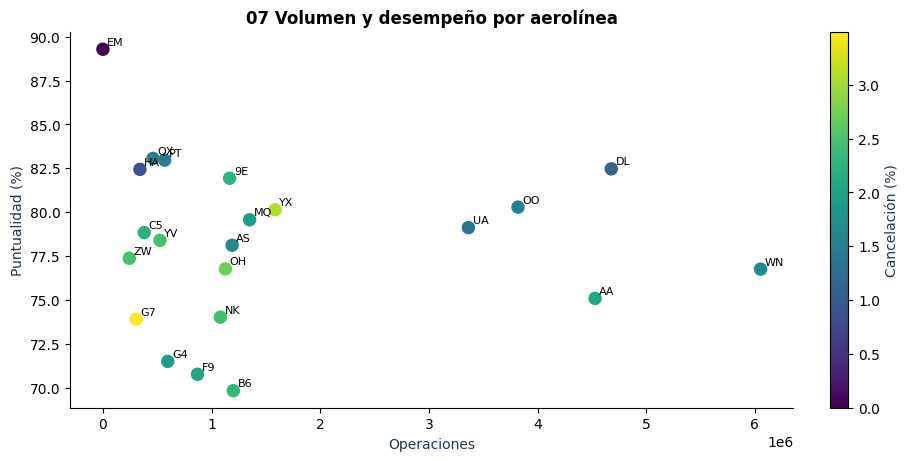

In [9]:
fig=figure(7,valid,raw,payload)
display(fig)
plt.close(fig)

**Interpretación:** WN concentra 6.052.588 operaciones con 76,75% de puntualidad; DL registra 4.678.479 y 82,47%. Un mayor volumen no implica por sí mismo mejor desempeño. EM es un caso de volumen mínimo, por lo que no sustenta una conclusión general.

## 08 Geografía de aeropuertos
**Pregunta:** ¿Dónde se localizan los hubs con los valores declarados más altos y bajos?

**Elección visual:** Se unen códigos IATA del bloque hubs con las coordenadas explícitas del HTML; área de los círculos proporcional a vuelos y color fijo para puntualidad.

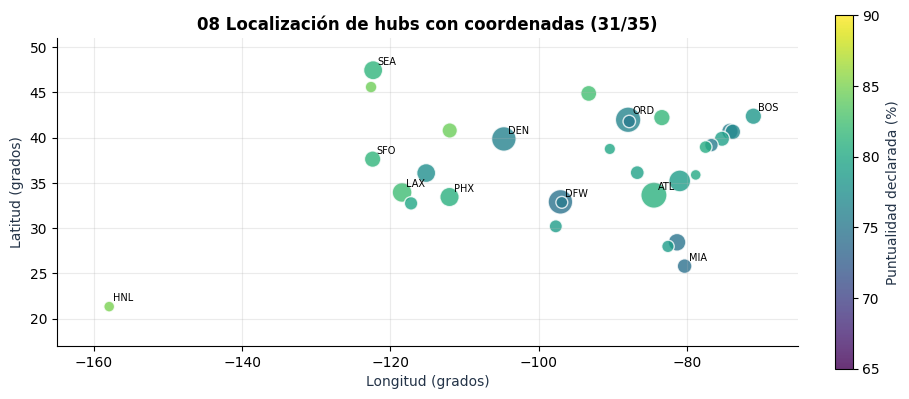

In [10]:
fig=figure(8,valid,raw,payload)
display(fig)
plt.close(fig)

**Interpretación:** Se ubican 31 de 35 hubs. IAH, LGA, DCA y FLL quedan en la tabla sin inventar coordenadas. HNL registra 85,0% y MIA 74,3% entre los ubicados; FLL declara 73,8% pero no aparece en el mapa. Hubs no tiene fecha ni desglose por aerolínea, por lo que esta vista es independiente.

## 09 Cobertura temporal
**Pregunta:** ¿Qué períodos están realmente disponibles?

**Elección visual:** Una matriz año por mes muestra el número de filas, no una supuesta tasa horaria. Los meses sin datos se representan con guion.

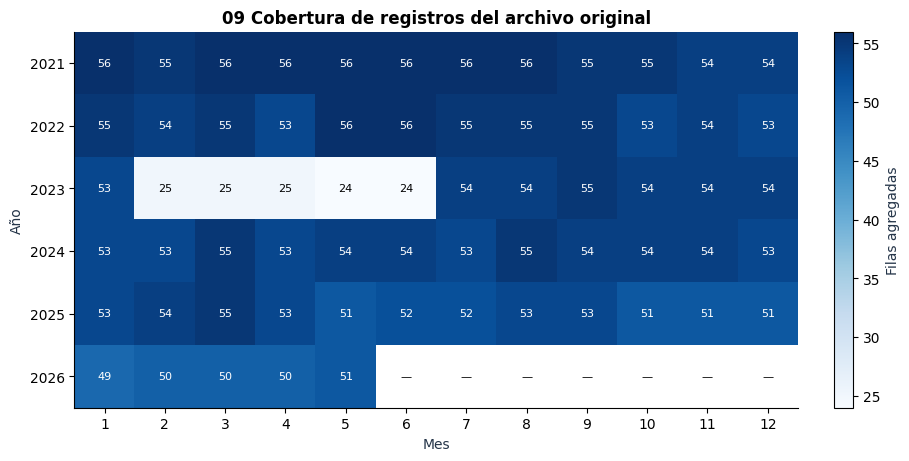

In [11]:
fig=figure(9,valid,raw,payload)
display(fig)
plt.close(fig)

**Interpretación:** El archivo cubre enero de 2021 a mayo de 2026. Junio–diciembre de 2026 están ausentes y no son ceros. No se compara el total de 2026 con un año completo; para comparaciones interanuales se usa abril y segmentos comunes.

## 10 Perfil horario auxiliar
**Pregunta:** ¿Qué patrón de demora declara el resumen horario?

**Elección visual:** Una línea usa solo los diez bloques presentes en hourly; no se construyen cruces día por hora que no existen.

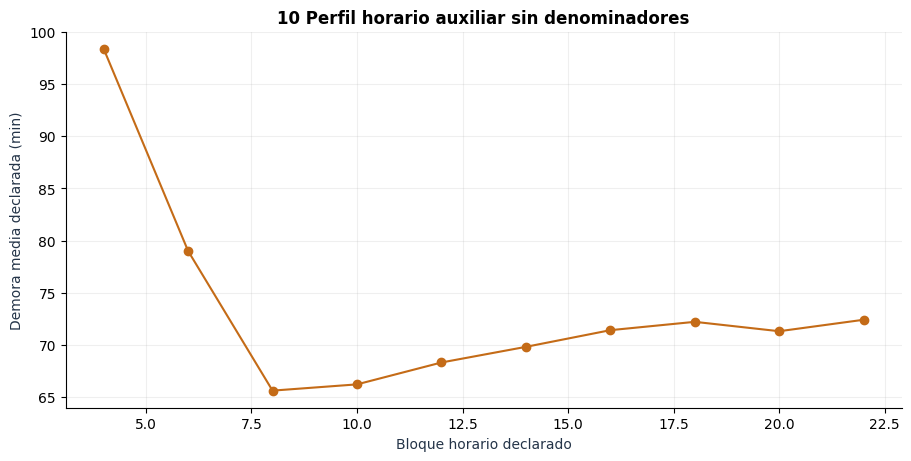

In [12]:
fig=figure(10,valid,raw,payload)
display(fig)
plt.close(fig)

**Interpretación:** El resumen declara 98,4 minutos a las 04:00 y 65,6 a las 08:00. No respalda afirmar que la demora siempre crece durante el día. Al faltar conteos, fecha, zona horaria y denominador, la lectura es exploratoria y no se calculan intervalos ni promedios ponderados.

## Panel de cuatro vistas conectadas y data app
Ejecuta `python -m streamlit run app.py`. Años, meses, aerolíneas, alcance y modo de calidad filtran una única tabla; actualizan los cuatro KPI y las vistas mensual, aerolínea con Wilson, alcance y causas. El mapa constituye la quinta visualización con selector propio de aeropuertos. No se conecta artificialmente con el cubo.

Prueba: seleccionar 2024 y AA; comprobar reducción de operaciones y una sola aerolínea; vaciar años y verificar mensaje sin división por cero; abrir Geografía y seleccionar ATL; regresar y comprobar estado de filtros. El archivo `verificar.py` automatiza los casos básicos. El CSV de selección permite contrastar los KPI.

El tema mantiene barra lateral, fondo azul oscuro, turquesa, jerarquía KPI→gráficos→interpretación del HTML. Las figuras del informe usan fondo claro para impresión. El color no es el único portador de información: ejes, etiquetas y tablas acompañan los gráficos.

In [13]:
summary=export()
print('Resultados exportados a resultados/')
assert len(valid)==3202
assert (valid.delayed60<=valid.delayed15).all()
assert np.isclose(valid.ops.sum(),35436522)
assert geo(payload).lat.notna().sum()==31
print('Controles de integridad correctos')

Resultados exportados a resultados/
Controles de integridad correctos


## Conclusión y límites
Priorizar la reparación del origen antes de decisiones operativas. Los datos validados muestran 78,08% de puntualidad y concentración de minutos en avión previo y aerolínea. Investigar julio de 2024; contrastar por rutas y mezcla operacional. No hay base para predicciones, causalidad, ranking ajustado ni estacionalidad de largo plazo. Solicitar microdatos o agregados consistentes con fechas, zonas horarias, códigos estatales, definiciones de alcance y conteos por aeropuerto/hora.

## Fuentes y despliegue
Fuentes de análisis: `data/data_vuelos_dashboard_final.json`, `referencias/dashboard_US_Flights_sidebar.html`, `referencias/HITO_2_rubrica.docx`. Los datos del HTML son material de diseño, no sustitutos del JSON. Instrucciones y URL pendiente en `FICHA_TECNICA.md`. Documentación de despliegue: https://docs.streamlit.io/deploy/streamlit-community-cloud/deploy-your-app/deploy (consultada el 20/10/2026).